In [4]:
%pip install pandas
%pip install numpy
%pip install scikit-learn
%pip install statsmodels
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


## Week 1

Included here: linear regression with polynomial terms, interaction terms, multicollinearity, variance inflation factor and regression, and categorical and continuous features

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

### Dataset 1: U.S. E-Commerce Records 2020

In [1]:
df_ecom = pd.read_csv(
    "US  E-commerce records 2020.csv",
    encoding="latin1"
)

print(df_ecom.shape)
display(df_ecom.head())

print("\nColumn names:")
print(df_ecom.columns.tolist())

print("\nMissing values:")
print(df_ecom.isnull().sum())


KeyboardInterrupt



For this analysis, I would predict Profit.


In [ ]:
target_ecom = "Profit"

numeric_ecom = [
    "Sales",
    "Quantity",
    "Discount"
]

categorical_ecom = [
    "Category",
    "Sub-Category",
    "Region",
    "Segment"
]

X_ecom = df_ecom[numeric_ecom + categorical_ecom]
y_ecom = df_ecom[target_ecom]

display(X_ecom.head())
display(y_ecom.head())

,Sales,Quantity,Discount,Category,Sub-Category,Region,Segment
0,48.896,4,0.2,Furniture,Furnishings,East,Consumer
1,474.430,11,0.0,Furniture,Furnishings,West,Consumer
2,3.600,2,0.0,Office Supplies,Binders,Central,Home Office
3,454.560,5,0.2,Office Supplies,Storage,Central,Consumer
4,141.420,5,0.6,Furniture,Furnishings,Central,Consumer


0      8.5568
1    199.2606
2      1.7280
3   -107.9580
4   -187.3815
Name: Profit, dtype: float64

             Sales  Quantity  Discount    Profit
Sales     1.000000  0.191127 -0.033516  0.532312
Quantity  0.191127  1.000000  0.019184  0.053766
Discount -0.033516  0.019184  1.000000 -0.218343
Profit    0.532312  0.053766 -0.218343  1.000000


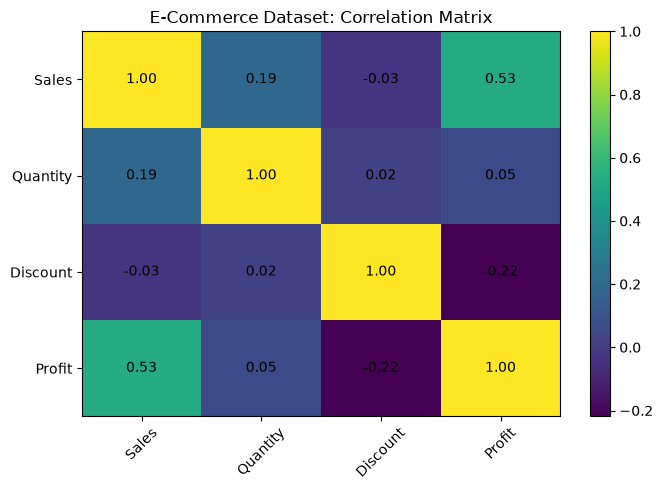

In [ ]:
corr_ecom = df_ecom[
    ["Sales", "Quantity", "Discount", "Profit"]
].corr()

print(corr_ecom)

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(corr_ecom, aspect="auto")

ax.set_xticks(range(len(corr_ecom.columns)))
ax.set_xticklabels(corr_ecom.columns, rotation=45)

ax.set_yticks(range(len(corr_ecom.index)))
ax.set_yticklabels(corr_ecom.index)

for i in range(len(corr_ecom.index)):
    for j in range(len(corr_ecom.columns)):
        ax.text(
            j,
            i,
            f"{corr_ecom.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.colorbar(im)
plt.title("E-Commerce Dataset: Correlation Matrix")
plt.tight_layout()
plt.show()

In [ ]:
X_vif_ecom = df_ecom[
    ["Sales", "Quantity", "Discount"]
].copy()

X_vif_ecom = sm.add_constant(X_vif_ecom)

vif_ecom = pd.DataFrame()
vif_ecom["Feature"] = X_vif_ecom.columns
vif_ecom["VIF"] = [
    variance_inflation_factor(X_vif_ecom.values, i)
    for i in range(X_vif_ecom.shape[1])
]

display(vif_ecom)

,Feature,VIF
0,const,1.000000
1,Sales,1.039407
2,Quantity,1.038621
3,Discount,1.001806


In [ ]:
X_train_ecom, X_test_ecom, y_train_ecom, y_test_ecom = train_test_split(
    X_ecom,
    y_ecom,
    test_size=0.20,
    random_state=42
)

preprocessor_ecom = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", numeric_ecom),
        (
            "categorical",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            categorical_ecom
        )
    ]
)

ecom_linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_ecom),
        ("regression", LinearRegression())
    ]
)

ecom_linear_model.fit(X_train_ecom, y_train_ecom)

pred_ecom_linear = ecom_linear_model.predict(X_test_ecom)

r2_ecom_linear = r2_score(y_test_ecom, pred_ecom_linear)
mae_ecom_linear = mean_absolute_error(y_test_ecom, pred_ecom_linear)
rmse_ecom_linear = np.sqrt(
    mean_squared_error(y_test_ecom, pred_ecom_linear)
)

print("Baseline Linear Regression")
print("R²:", round(r2_ecom_linear, 4))
print("MAE:", round(mae_ecom_linear, 2))
print("RMSE:", round(rmse_ecom_linear, 2))


Baseline Linear Regression
R²: 0.2878
MAE: 67.91
RMSE: 297.93


In [ ]:
poly_preprocessor_ecom = ColumnTransformer(
    transformers=[
        (
            "numeric",
            PolynomialFeatures(
                degree=2,
                include_bias=False
            ),
            numeric_ecom
        ),
        (
            "categorical",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            categorical_ecom
        )
    ]
)

ecom_poly_model = Pipeline(
    steps=[
        ("preprocessor", poly_preprocessor_ecom),
        ("regression", LinearRegression())
    ]
)

ecom_poly_model.fit(X_train_ecom, y_train_ecom)

pred_ecom_poly = ecom_poly_model.predict(X_test_ecom)

r2_ecom_poly = r2_score(y_test_ecom, pred_ecom_poly)
mae_ecom_poly = mean_absolute_error(y_test_ecom, pred_ecom_poly)
rmse_ecom_poly = np.sqrt(
    mean_squared_error(y_test_ecom, pred_ecom_poly)
)

print("Polynomial / Interaction Model")
print("R²:", round(r2_ecom_poly, 4))
print("MAE:", round(mae_ecom_poly, 2))
print("RMSE:", round(rmse_ecom_poly, 2))

Polynomial / Interaction Model
R²: 0.8492
MAE: 36.54
RMSE: 137.08


### Now Let's compare teh models:

In [ ]:
comparison_ecom_w1 = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Polynomial + Interaction Regression"
    ],
    "R2": [
        r2_ecom_linear,
        r2_ecom_poly
    ],
    "MAE": [
        mae_ecom_linear,
        mae_ecom_poly
    ],
    "RMSE": [
        rmse_ecom_linear,
        rmse_ecom_poly
    ]
})

display(comparison_ecom_w1)

,Model,R2,MAE,RMSE
0,Linear Regression,0.287760,67.912815,297.933206
1,Polynomial + Interaction Regression,0.849224,36.537830,137.079239


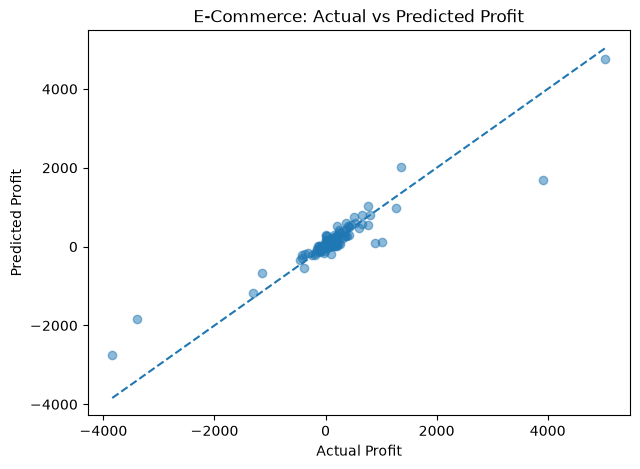

In [ ]:
plt.figure(figsize=(7, 5))

plt.scatter(
    y_test_ecom,
    pred_ecom_poly,
    alpha=0.5
)

minimum = min(y_test_ecom.min(), pred_ecom_poly.min())
maximum = max(y_test_ecom.max(), pred_ecom_poly.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Profit")
plt.ylabel("Predicted Profit")
plt.title("E-Commerce: Actual vs Predicted Profit")
plt.show()

### Dataset 2: Retail Store Inventory

In [ ]:
df_retail = pd.read_csv(
    "retail_store_inventory.csv",
    encoding="latin1"
)

print(df_retail.shape)
display(df_retail.head())

print("\nColumn names:")
print(df_retail.columns.tolist())

print("\nMissing values:")
print(df_retail.isnull().sum())

(73100, 15)


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer



Column names:
['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast', 'Price', 'Discount', 'Weather Condition', 'Holiday/Promotion', 'Competitor Pricing', 'Seasonality']

Missing values:
Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Demand Forecast       0
Price                 0
Discount              0
Weather Condition     0
Holiday/Promotion     0
Competitor Pricing    0
Seasonality           0
dtype: int64


In [ ]:
target_retail = "Units Sold"

numeric_retail = [
    "Demand Forecast",
    "Inventory Level",
    "Units Ordered",
    "Price",
    "Discount",
    "Competitor Pricing",
    "Holiday/Promotion"
]

categorical_retail = [
    "Category",
    "Region",
    "Weather Condition",
    "Seasonality"
]

X_retail = df_retail[
    numeric_retail + categorical_retail
]

y_retail = df_retail[target_retail]

display(X_retail.head())

,Demand Forecast,Inventory Level,Units Ordered,Price,Discount,Competitor Pricing,Holiday/Promotion,Category,Region,Weather Condition,Seasonality
0,135.47,231,55,33.50,20,29.69,0,Groceries,North,Rainy,Autumn
1,144.04,204,66,63.01,20,66.16,0,Toys,South,Sunny,Autumn
2,74.02,102,51,27.99,10,31.32,1,Toys,West,Sunny,Summer
3,62.18,469,164,32.72,10,34.74,1,Toys,North,Cloudy,Autumn
4,9.26,166,135,73.64,0,68.95,0,Electronics,East,Sunny,Summer


                    Inventory Level  Units Sold  Units Ordered  \
Inventory Level            1.000000    0.589995       0.001060   
Units Sold                 0.589995    1.000000      -0.000930   
Units Ordered              0.001060   -0.000930       1.000000   
Demand Forecast            0.588561    0.996853      -0.001102   
Price                      0.009140    0.001082       0.004212   
Discount                   0.004889    0.002576      -0.000938   
Holiday/Promotion          0.003411   -0.000374       0.005446   
Competitor Pricing         0.009365    0.001259       0.004596   

                    Demand Forecast     Price  Discount  Holiday/Promotion  \
Inventory Level            0.588561  0.009140  0.004889           0.003411   
Units Sold                 0.996853  0.001082  0.002576          -0.000374   
Units Ordered             -0.001102  0.004212 -0.000938           0.005446   
Demand Forecast            1.000000  0.000675  0.002338          -0.000526   
Price          

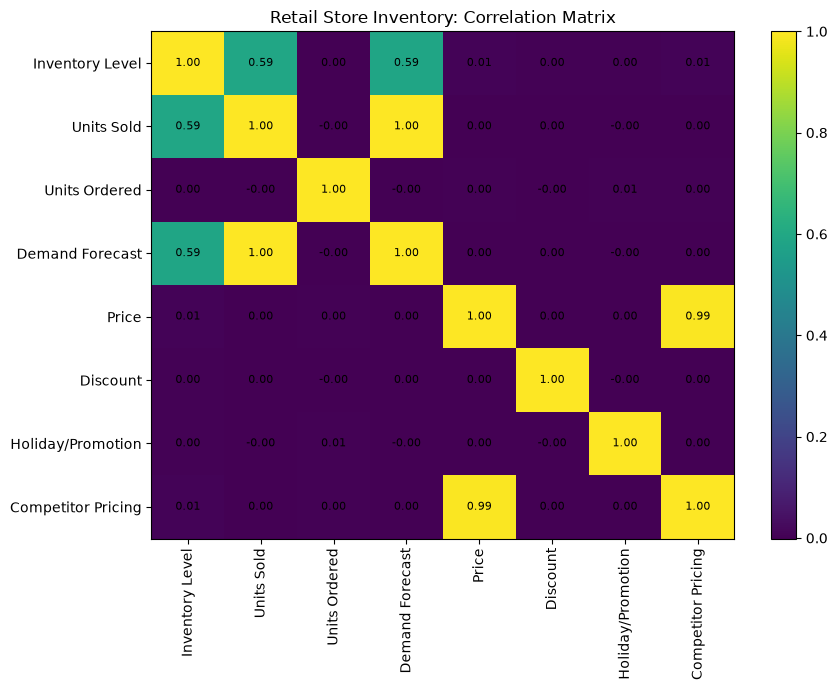

In [ ]:
retail_numeric_for_corr = [
    "Inventory Level",
    "Units Sold",
    "Units Ordered",
    "Demand Forecast",
    "Price",
    "Discount",
    "Holiday/Promotion",
    "Competitor Pricing"
]

corr_retail = df_retail[
    retail_numeric_for_corr
].corr()

print(corr_retail)

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr_retail, aspect="auto")

ax.set_xticks(range(len(corr_retail.columns)))
ax.set_xticklabels(
    corr_retail.columns,
    rotation=90
)

ax.set_yticks(range(len(corr_retail.index)))
ax.set_yticklabels(corr_retail.index)

for i in range(len(corr_retail.index)):
    for j in range(len(corr_retail.columns)):
        ax.text(
            j,
            i,
            f"{corr_retail.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

plt.colorbar(im)
plt.title("Retail Store Inventory: Correlation Matrix")
plt.tight_layout()
plt.show()

In [ ]:
X_vif_retail = df_retail[
    [
        "Demand Forecast",
        "Inventory Level",
        "Units Ordered",
        "Price",
        "Discount",
        "Competitor Pricing",
        "Holiday/Promotion"
    ]
].copy()

X_vif_retail = sm.add_constant(X_vif_retail)

vif_retail = pd.DataFrame()

vif_retail["Feature"] = X_vif_retail.columns

vif_retail["VIF"] = [
    variance_inflation_factor(
        X_vif_retail.values,
        i
    )
    for i in range(X_vif_retail.shape[1])
]

display(vif_retail)

,Feature,VIF
0,const,1.000000
1,Demand Forecast,1.530072
2,Inventory Level,1.530250
3,Units Ordered,1.000068
4,Price,82.221564
5,Discount,1.000045
6,Competitor Pricing,82.222125
7,Holiday/Promotion,1.000070


In [ ]:
X_train_retail, X_test_retail, y_train_retail, y_test_retail = train_test_split(
    X_retail,
    y_retail,
    test_size=0.20,
    random_state=42
)

preprocessor_retail = ColumnTransformer(
    transformers=[
        (
            "numeric",
            "passthrough",
            numeric_retail
        ),
        (
            "categorical",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            categorical_retail
        )
    ]
)

retail_linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_retail),
        ("regression", LinearRegression())
    ]
)

retail_linear_model.fit(
    X_train_retail,
    y_train_retail
)

pred_retail_linear = retail_linear_model.predict(
    X_test_retail
)

r2_retail_linear = r2_score(
    y_test_retail,
    pred_retail_linear
)

mae_retail_linear = mean_absolute_error(
    y_test_retail,
    pred_retail_linear
)

rmse_retail_linear = np.sqrt(
    mean_squared_error(
        y_test_retail,
        pred_retail_linear
    )
)

print("Baseline Linear Regression")
print("R²:", round(r2_retail_linear, 4))
print("MAE:", round(mae_retail_linear, 2))
print("RMSE:", round(rmse_retail_linear, 2))

Baseline Linear Regression
R²: 0.9938
MAE: 7.42
RMSE: 8.6


In [ ]:
poly_preprocessor_retail = ColumnTransformer(
    transformers=[
        (
            "numeric",
            PolynomialFeatures(
                degree=2,
                include_bias=False
            ),
            numeric_retail
        ),
        (
            "categorical",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            categorical_retail
        )
    ]
)

retail_poly_model = Pipeline(
    steps=[
        ("preprocessor", poly_preprocessor_retail),
        ("regression", LinearRegression())
    ]
)

retail_poly_model.fit(
    X_train_retail,
    y_train_retail
)

pred_retail_poly = retail_poly_model.predict(
    X_test_retail
)

r2_retail_poly = r2_score(
    y_test_retail,
    pred_retail_poly
)

mae_retail_poly = mean_absolute_error(
    y_test_retail,
    pred_retail_poly
)

rmse_retail_poly = np.sqrt(
    mean_squared_error(
        y_test_retail,
        pred_retail_poly
    )
)

print("Polynomial / Interaction Model")
print("R²:", round(r2_retail_poly, 4))
print("MAE:", round(mae_retail_poly, 2))
print("RMSE:", round(rmse_retail_poly, 2))

Polynomial / Interaction Model
R²: 0.9938
MAE: 7.37
RMSE: 8.55


## Now let's compare everything for this week for both of the datasets

In [ ]:
week1_summary = pd.DataFrame({
    "Dataset": [
        "E-Commerce",
        "E-Commerce",
        "Retail Inventory",
        "Retail Inventory"
    ],
    "Model": [
        "Linear",
        "Polynomial + Interactions",
        "Linear",
        "Polynomial + Interactions"
    ],
    "R2": [
        r2_ecom_linear,
        r2_ecom_poly,
        r2_retail_linear,
        r2_retail_poly
    ],
    "MAE": [
        mae_ecom_linear,
        mae_ecom_poly,
        mae_retail_linear,
        mae_retail_poly
    ],
    "RMSE": [
        rmse_ecom_linear,
        rmse_ecom_poly,
        rmse_retail_linear,
        rmse_retail_poly
    ]
})

display(week1_summary)

,Dataset,Model,R2,MAE,RMSE
0,E-Commerce,Linear,0.287760,67.912815,297.933206
1,E-Commerce,Polynomial + Interactions,0.849224,36.537830,137.079239
2,Retail Inventory,Linear,0.993752,7.417890,8.600740
3,Retail Inventory,Polynomial + Interactions,0.993821,7.368257,8.553425


During this week's analysis, I found a major difference between these two datasets. The Retail Store Inventory dataset works extremely well with linear regression. Adding polynomial and interaction terms improved the result only a little. This says that most of the useful relationship in this dataset may be linear.
The E-Commerce dataset behaved differently. The basic model produced a much lower R2. But when I added polynomial, it increased. This means that the relationships between Profit and the predictors are more complicated and cannot be represented as good by simple linear relationships. 
This all is similar to my previous work, where I found that the e-commerce dataset seemed to be more noisy than the retail dataset.

## Week 2

Lasso, Ridge, Elastic net

### Dataset 1: U.S. E-Commerce Records 2020

In [ ]:
numeric_ecom = [
    "Sales",
    "Quantity",
    "Discount"
]

categorical_ecom = [
    "Category",
    "Sub-Category",
    "Region",
    "Segment"
]

X_ecom = df_ecom[
    numeric_ecom + categorical_ecom
]

y_ecom = df_ecom["Profit"]

X_train_ecom, X_test_ecom, y_train_ecom, y_test_ecom = train_test_split(
    X_ecom,
    y_ecom,
    test_size=0.20,
    random_state=42
)

In [ ]:
preprocessor_ecom = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            numeric_ecom
        ),
        (
            "categorical",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            categorical_ecom
        )
    ]
)

In [ ]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.model_selection import train_test_split, GridSearchCV

In [ ]:
# Ridge

ridge_ecom = Pipeline(
    steps=[
        ("preprocessor", preprocessor_ecom),
        ("model", Ridge())
    ]
)

ridge_params_ecom = {
    "model__alpha": [
        0.01,
        0.1,
        1,
        10,
        100
    ]
}

ridge_grid_ecom = GridSearchCV(
    ridge_ecom,
    ridge_params_ecom,
    cv=5,
    scoring="r2"
)

ridge_grid_ecom.fit(
    X_train_ecom,
    y_train_ecom
)

ridge_pred_ecom = ridge_grid_ecom.predict(
    X_test_ecom
)

print("Best Ridge alpha:",
      ridge_grid_ecom.best_params_)

print(
    "Ridge R²:",
    round(
        r2_score(
            y_test_ecom,
            ridge_pred_ecom
        ),
        4
    )
)

Best Ridge alpha: {'model__alpha': 1}
Ridge R²: 0.2846


In [ ]:
# Lasso:

lasso_ecom = Pipeline(
    steps=[
        ("preprocessor", preprocessor_ecom),
        (
            "model",
            Lasso(max_iter=20000)
        )
    ]
)

lasso_params_ecom = {
    "model__alpha": [
        0.0001,
        0.001,
        0.01,
        0.1,
        1,
        10
    ]
}

lasso_grid_ecom = GridSearchCV(
    lasso_ecom,
    lasso_params_ecom,
    cv=5,
    scoring="r2"
)

lasso_grid_ecom.fit(
    X_train_ecom,
    y_train_ecom
)

lasso_pred_ecom = lasso_grid_ecom.predict(
    X_test_ecom
)

print("Best Lasso alpha:",
      lasso_grid_ecom.best_params_)

print(
    "Lasso R²:",
    round(
        r2_score(
            y_test_ecom,
            lasso_pred_ecom
        ),
        4
    )
)

Best Lasso alpha: {'model__alpha': 0.1}
Lasso R²: 0.2838


In [ ]:
# Elastic Net:

elastic_ecom = Pipeline(
    steps=[
        ("preprocessor", preprocessor_ecom),
        (
            "model",
            ElasticNet(max_iter=20000)
        )
    ]
)

elastic_params_ecom = {
    "model__alpha": [
        0.0001,
        0.001,
        0.01,
        0.1,
        1
    ],
    "model__l1_ratio": [
        0.1,
        0.5,
        0.9
    ]
}

elastic_grid_ecom = GridSearchCV(
    elastic_ecom,
    elastic_params_ecom,
    cv=5,
    scoring="r2"
)

elastic_grid_ecom.fit(
    X_train_ecom,
    y_train_ecom
)

elastic_pred_ecom = elastic_grid_ecom.predict(
    X_test_ecom
)

print(
    "Best Elastic Net parameters:",
    elastic_grid_ecom.best_params_
)

print(
    "Elastic Net R²:",
    round(
        r2_score(
            y_test_ecom,
            elastic_pred_ecom
        ),
        4
    )
)

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:786: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.182535e+05, tolerance: 1.005e+04
  model = cd_fast.sparse_enet_coordinate_descent(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:786: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.970430e+05, tolerance: 8.907e+03
  model = cd_fast.sparse_enet_coordinate_descent(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:786: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increa

Best Elastic Net parameters: {'model__alpha': 0.01, 'model__l1_ratio': 0.9}
Elastic Net R²: 0.2812


### Comparing the models:

In [ ]:
ecom_week2_results = pd.DataFrame({
    "Model": [
        "Ridge",
        "Lasso",
        "Elastic Net"
    ],
    "R2": [
        r2_score(
            y_test_ecom,
            ridge_pred_ecom
        ),
        r2_score(
            y_test_ecom,
            lasso_pred_ecom
        ),
        r2_score(
            y_test_ecom,
            elastic_pred_ecom
        )
    ],
    "MAE": [
        mean_absolute_error(
            y_test_ecom,
            ridge_pred_ecom
        ),
        mean_absolute_error(
            y_test_ecom,
            lasso_pred_ecom
        ),
        mean_absolute_error(
            y_test_ecom,
            elastic_pred_ecom
        )
    ],
    "RMSE": [
        np.sqrt(
            mean_squared_error(
                y_test_ecom,
                ridge_pred_ecom
            )
        ),
        np.sqrt(
            mean_squared_error(
                y_test_ecom,
                lasso_pred_ecom
            )
        ),
        np.sqrt(
            mean_squared_error(
                y_test_ecom,
                elastic_pred_ecom
            )
        )
    ]
})

display(ecom_week2_results)

,Model,R2,MAE,RMSE
0,Ridge,0.284639,67.974136,298.585204
1,Lasso,0.283800,67.499712,298.760431
2,Elastic Net,0.281217,67.979285,299.298588


## Retail Inventory Dataset

In [ ]:
numeric_retail = [
    "Demand Forecast",
    "Inventory Level",
    "Units Ordered",
    "Price",
    "Discount",
    "Competitor Pricing",
    "Holiday/Promotion"
]

categorical_retail = [
    "Category",
    "Region",
    "Weather Condition",
    "Seasonality"
]

X_retail = df_retail[
    numeric_retail + categorical_retail
]

y_retail = df_retail["Units Sold"]

X_train_retail, X_test_retail, y_train_retail, y_test_retail = train_test_split(
    X_retail,
    y_retail,
    test_size=0.20,
    random_state=42
)

In [ ]:
preprocessor_retail = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            numeric_retail
        ),
        (
            "categorical",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            categorical_retail
        )
    ]
)

In [ ]:
# Ridge for retail dataset:
ridge_retail = Pipeline(
    steps=[
        ("preprocessor", preprocessor_retail),
        ("model", Ridge())
    ]
)

ridge_params_retail = {
    "model__alpha": [
        0.01,
        0.1,
        1,
        10,
        100
    ]
}

ridge_grid_retail = GridSearchCV(
    ridge_retail,
    ridge_params_retail,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

ridge_grid_retail.fit(
    X_train_retail,
    y_train_retail
)

ridge_pred_retail = ridge_grid_retail.predict(
    X_test_retail
)

print(
    "Best Ridge parameters:",
    ridge_grid_retail.best_params_
)

Best Ridge parameters: {'model__alpha': 0.1}


In [ ]:
# Lasso:

lasso_retail = Pipeline(
    steps=[
        ("preprocessor", preprocessor_retail),
        (
            "model",
            Lasso(max_iter=20000)
        )
    ]
)

lasso_params_retail = {
    "model__alpha": [
        0.0001,
        0.001,
        0.01,
        0.1,
        1,
        10
    ]
}

lasso_grid_retail = GridSearchCV(
    lasso_retail,
    lasso_params_retail,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

lasso_grid_retail.fit(
    X_train_retail,
    y_train_retail
)

lasso_pred_retail = lasso_grid_retail.predict(
    X_test_retail
)

print(
    "Best Lasso parameters:",
    lasso_grid_retail.best_params_
)

Best Lasso parameters: {'model__alpha': 0.1}


In [ ]:
# Elastic:

elastic_retail = Pipeline(
    steps=[
        ("preprocessor", preprocessor_retail),
        (
            "model",
            ElasticNet(max_iter=20000)
        )
    ]
)

elastic_params_retail = {
    "model__alpha": [
        0.0001,
        0.001,
        0.01,
        0.1,
        1
    ],
    "model__l1_ratio": [
        0.1,
        0.5,
        0.9
    ]
}

elastic_grid_retail = GridSearchCV(
    elastic_retail,
    elastic_params_retail,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

elastic_grid_retail.fit(
    X_train_retail,
    y_train_retail
)

elastic_pred_retail = elastic_grid_retail.predict(
    X_test_retail
)

print(
    "Best Elastic Net parameters:",
    elastic_grid_retail.best_params_
)

Best Elastic Net parameters: {'model__alpha': 0.001, 'model__l1_ratio': 0.9}


## Let's compare everything below:

In [ ]:
retail_week2_results = pd.DataFrame({
    "Model": [
        "Ridge",
        "Lasso",
        "Elastic Net"
    ],
    "R2": [
        r2_score(
            y_test_retail,
            ridge_pred_retail
        ),
        r2_score(
            y_test_retail,
            lasso_pred_retail
        ),
        r2_score(
            y_test_retail,
            elastic_pred_retail
        )
    ],
    "MAE": [
        mean_absolute_error(
            y_test_retail,
            ridge_pred_retail
        ),
        mean_absolute_error(
            y_test_retail,
            lasso_pred_retail
        ),
        mean_absolute_error(
            y_test_retail,
            elastic_pred_retail
        )
    ],
    "RMSE": [
        np.sqrt(
            mean_squared_error(
                y_test_retail,
                ridge_pred_retail
            )
        ),
        np.sqrt(
            mean_squared_error(
                y_test_retail,
                lasso_pred_retail
            )
        ),
        np.sqrt(
            mean_squared_error(
                y_test_retail,
                elastic_pred_retail
            )
        )
    ]
})

display(retail_week2_results)

,Model,R2,MAE,RMSE
0,Ridge,0.993752,7.417881,8.600737
1,Lasso,0.993753,7.417595,8.599849
2,Elastic Net,0.993753,7.417269,8.600420


In [ ]:
week2_summary = pd.DataFrame({
    "Dataset": [
        "E-Commerce",
        "E-Commerce",
        "E-Commerce",
        "Retail Inventory",
        "Retail Inventory",
        "Retail Inventory"
    ],
    "Model": [
        "Ridge",
        "Lasso",
        "Elastic Net",
        "Ridge",
        "Lasso",
        "Elastic Net"
    ],
    "R2": [
        r2_score(y_test_ecom, ridge_pred_ecom),
        r2_score(y_test_ecom, lasso_pred_ecom),
        r2_score(y_test_ecom, elastic_pred_ecom),
        r2_score(y_test_retail, ridge_pred_retail),
        r2_score(y_test_retail, lasso_pred_retail),
        r2_score(y_test_retail, elastic_pred_retail)
    ]
})

display(week2_summary)

,Dataset,Model,R2
0,E-Commerce,Ridge,0.284639
1,E-Commerce,Lasso,0.283800
2,E-Commerce,Elastic Net,0.281217
3,Retail Inventory,Ridge,0.993752
4,Retail Inventory,Lasso,0.993753
5,Retail Inventory,Elastic Net,0.993753


During Week 2 I compared Ridge, Lasso, and Elastic Net regressions for both of my datasets. The results again showed a significant difference between them. For the Retail Store Inventory dataset, all three models achieved an R2 of approximately 0.994. There was almost no difference among Ridge, Lasso, and Elastic Net. This is probably because Demand Forecast already explains a very large part of the variation in Units Sold. So regularization does not provide a major improvement because the relationship is already very strong.

For the E-Commerce dataset, Ridge, Lasso, and Elastic Net produced an R2 of only around 0.28. This is lower than the retail dataset. It also supports the conclusions from my previous week that the e-commerce data is more noisy and less clear relationships between variables.